## Project Title & Domain

#### **Project Title:** Airline Customer Satisfaction & Service Quality Analysis
#### **Domain:** Airline Industry (Aviation)

## Project Overview

This project focuses on analyzing airline passenger ratings to evaluate customer satisfaction and service quality.It aims to identify overall passenger satisfaction levels, compare ratings across different service categories, and examine how service ratings relate to overall customer satisfaction.The project also compares ratings based on airline, traveller type, seat type, and recommendation status to identify patterns in passenger satisfaction.

The analysis will use Python and its data analysis libraries to identify satisfaction patterns and service areas that may require improvement.

## Business problem

Airlines need to know whether passengers are satisfied with their services and which areas need improvement. Passenger ratings help airlines understand how customers feel about their overall experience and individual services.

By analyzing these ratings, we can identify services with lower ratings, compare overall ratings with customer recommendations, and understand differences in satisfaction across airlines and passenger groups.

## Project Objective

- Classify overall ratings into Poor (1–2), Medium (3–4), and High (5–10) categories and calculate the percentage of ratings in each category.
    
- Analyse the overall customer satisfaction distribution to understand the proportion of satisfied and dissatisfied passengers.
    
- Compare the average ratings of six service categories and identify the three lowest-rated service areas.
    
- Compare the average overall ratings of customers who recommend the airline with those who do not.
    
- Compare average overall ratings across airlines, considering only airlines with a sufficient number of reviews, and identify the highest- and lowest-rated airlines.
    
- Conduct a detailed analysis of Hainan Airlines, the highest-rated airline, by comparing overall ratings based on trip verification and recommendation status.
    
- Analyse the relationship between different service quality factors using correlation analysis.
    
- Compare average overall ratings across different traveller types and seat types to understand variations in customer experience.
    
- Analyse customer satisfaction across Indian airlines based on traveller types and seat categories.
    
- Compare service quality ratings between highly satisfied and poorly satisfied passengers across Indian airlines to identify areas requiring improvement.


## Business Value & Use Case

This project can benefit airline management, customer experience teams,
and service quality managers.

The analysis can help us find services with low ratings and understand passenger satisfaction. It can also help us compare passenger experiences and identify which services need improvement. The results may help airlines make better decisions to improve service quality and customer satisfaction.

## Dataset Information


- **Source URL:** https://data.mendeley.com/datasets/vgjk58vf8h/1
  
- **Origin:** The dataset was collected from Skytrax airline passenger reviews.

- **Orginal File Format:** Excel (.xlsx)

- **Format Used for Analysis:** CSV (.csv)
 
- **Rows and Columns:** The dataset contains 64,740 rows and 19 columns.

- **Key Fields:** Overall rating, airline name, seat comfort, cabin staff service, food and beverages, inflight entertainment, ground service,value for money,traveller type,seat type,and recommendation status.

- **Rating Scales:** Overall passenger rating (over_all_rating): 1–10.Individual service ratings across the seven service categories: 1–5.

- **Record Description:** Each row represents one passenger review of an airline,including the passenger's ratings and related  review information.

## Planned Analysis

- **Data Cleaning:** Check and handle missing values, duplicate records, incorrect data types, and unusual values where necessary and standardize inconsistent text values where required.

- **Feature Engineering:** Create new columns such as satisfaction level based on overall ratings and average service rating based on available service ratings.

- **Exploratory Data Analysis (EDA):** Perform univariate, bivariate, and multivariate analysis to understand passenger ratings and satisfaction patterns.

- **Metrics:** Calculate satisfaction percentages and average ratings for different service categories. Compare ratings across airlines, traveller types, seat types, and recommendation status.

- **Charts:** Use Matplotlib, Seaborn, and Plotly to create suitable static and interactive charts, including bar charts and pie charts, to explore patterns and present findings clearly.

## Scope & Limitations

### Scope

- This project focuses on analyzing passenger ratings to understand customer satisfaction and airline service quality.

- It includes comparisons across service categories, airlines, traveller types, seat types, and recommendation status.

- The project includes data cleaning, feature creation, exploratory data analysis, and data visualization.

### Limitations

- The analysis depends on the information available in the dataset.
  
- Missing or incomplete ratings may affect some calculations.
  
- The results represent the available passenger reviews and may not reflect the experience of every airline passenger.
  
- The project focuses mainly on ratings and does not verify actual flight delays, cancellations, or other operational issues.

### Assumptions

- The ratings provided in the dataset are treated as recorded passenger feedback.

  
- The available service-rating columns are used to compare different aspects of airline service quality.

In [2]:
#import required libraries

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px

In [3]:
df=pd.read_csv(r'C:\Users\matus\Downloads\Main Project\Skytrax Airline Review Data.csv')

In [4]:
df.head()


,review_date,over_all_rating,review_header,trip_verified,review_text,aircraft,type_of_traveller,seat_type,route,date_flown,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,wifi__connectivity,value_for_money,recommended,airline_name
0,04-08-2025,1.0,"""showed zero empathy for passengers""",Trip Verified,My afternoon flight was delayed and eventuall...,NaN,business,economy_class,dubai_to_kochi,august_2025,1.0,2.0,2.0,2.0,1.0,1.0,1.0,no,spicejet
1,21-07-2025,2.0,"""Extremely dissatisfied""",Trip Verified,The flight was postponed 3 times with insuffi...,NaN,family_leisure,economy_class,pune_to_dubai,july_2025,1.0,3.0,NaN,NaN,3.0,NaN,2.0,no,spicejet
2,19-04-2025,2.0,"""Very bad experience""",Trip Verified,They will charge you for your hand baggage if...,NaN,business,economy_class,mumbai_to_kolkata,april_2025,3.0,3.0,3.0,NaN,1.0,NaN,2.0,no,spicejet
3,12-03-2025,1.0,“What a difficult airline”,Trip Verified,The flight was delayed from 15:20 to 16:25. I...,NaN,business,economy_class,"pune,_india_to_new_delhi,_india",march_2025,3.0,4.0,NaN,NaN,5.0,NaN,1.0,no,spicejet
4,02-03-2025,2.0,“Poor chaotic boarding”,Trip Verified,No crowd control and boarding was like cattle...,boeing_747,solo_leisure,economy_class,mumbai_to_new_delhi,march_2025,3.0,1.0,3.0,NaN,1.0,NaN,2.0,no,spicejet


In [5]:
df.shape

(64740, 19)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64740 entries, 0 to 64739
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   review_date             64740 non-null  str    
 1   over_all_rating         64624 non-null  float64
 2   review_header           64740 non-null  str    
 3   trip_verified           53047 non-null  str    
 4   review_text             64593 non-null  str    
 5   aircraft                27973 non-null  str    
 6   type_of_traveller       62102 non-null  str    
 7   seat_type               64702 non-null  str    
 8   route                   61879 non-null  str    
 9   date_flown              62004 non-null  str    
 10  seat_comfort            61265 non-null  float64
 11  cabin_staff_service     61038 non-null  float64
 12  food__beverages         52149 non-null  float64
 13  inflight_entertainment  43578 non-null  float64
 14  ground_service          60053 non-null  float64
 

In [7]:
df.dtypes

review_date                   str
over_all_rating           float64
review_header                 str
trip_verified                 str
review_text                   str
aircraft                      str
type_of_traveller             str
seat_type                     str
route                         str
date_flown                    str
seat_comfort              float64
cabin_staff_service       float64
food__beverages           float64
inflight_entertainment    float64
ground_service            float64
wifi__connectivity        float64
value_for_money           float64
recommended                   str
airline_name                  str
dtype: object

In [8]:
df.columns

Index(['review_date', 'over_all_rating', 'review_header', 'trip_verified',
       'review_text', 'aircraft', 'type_of_traveller', 'seat_type', 'route',
       'date_flown', 'seat_comfort', 'cabin_staff_service', 'food__beverages',
       'inflight_entertainment', 'ground_service', 'wifi__connectivity',
       'value_for_money', 'recommended', 'airline_name'],
      dtype='str')

### Intial description

- The dataset contains 64,740 rows and 19 columns, including passenger reviews, overall ratings, service ratings, and airline information. It contains 11 text columns and 8 numerical columns. Some columns have missing values, and the review dates are stored as text, so data type conversion and standardization may be considered during data cleaning.


## Data Cleaning and Preprocessing¶


In [9]:
df_data=df.copy()


- Created a copy of the original dataset and stored it in a new DataFrame named df_data.
- This helps preserve the original dataset (df) without making any changes to it.
- All further data cleaning and analysis are performed on the copied DataFrame (df_data), keeping the original data safe for future reference.

In [10]:
# Checking missing values

df_data.isnull().sum()


review_date                   0
over_all_rating             116
review_header                 0
trip_verified             11693
review_text                 147
aircraft                  36767
type_of_traveller          2638
seat_type                    38
route                      2861
date_flown                 2736
seat_comfort               3475
cabin_staff_service        3702
food__beverages           12591
inflight_entertainment    21162
ground_service             4687
wifi__connectivity        41118
value_for_money              22
recommended                   1
airline_name                  0
dtype: int64

Observations:
- Checked the number of missing values in each column to understand the completeness of the dataset.
- Missing values were identified in both numerical and categorical columns.
- The wifi__connectivity column had the highest number of missing values (41,118), followed by aircraft (36,767) and inflight_entertainment (21,162).
- Other columns contained varying numbers of missing values, which were reviewed to decide the appropriate missing-value treatment.
- This step helped identify columns requiring missing-value handling and supported decisions about retaining or dropping columns during data cleaning.

#### Duplicate Handling

In [11]:
# identify and remove duplicates

df_data.duplicated().sum()

np.int64(64)

In [12]:
df_data[df_data.duplicated(keep=False)]

,review_date,over_all_rating,review_header,trip_verified,review_text,aircraft,type_of_traveller,seat_type,route,date_flown,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,wifi__connectivity,value_for_money,recommended,airline_name
3749,18-02-2015,8.0,Philippine Airlines customer review,NaN,The price is the same as Cebu Pacific but PAL...,NaN,NaN,economy_class,NaN,NaN,4.0,4.0,4.0,1.0,NaN,NaN,4.0,yes,philippine-airlines
3750,18-02-2015,8.0,Philippine Airlines customer review,NaN,The price is the same as Cebu Pacific but PAL...,NaN,NaN,economy_class,NaN,NaN,4.0,4.0,4.0,1.0,NaN,NaN,4.0,yes,philippine-airlines
5639,16-04-2015,6.0,Air China customer review,NaN,Used miles for this trip as CA First was 7500...,NaN,NaN,first_class,NaN,NaN,4.0,4.0,2.0,2.0,NaN,NaN,5.0,no,air-china
5640,16-04-2015,6.0,Air China customer review,NaN,Used miles for this trip as CA First was 7500...,NaN,NaN,first_class,NaN,NaN,4.0,4.0,2.0,2.0,NaN,NaN,5.0,no,air-china
7825,24-02-2015,5.0,Jetstar Airways customer review,NaN,Home 19 Feb JQ030. Great Crew and excellent s...,NaN,NaN,NaN,NaN,NaN,1.0,5.0,4.0,2.0,NaN,NaN,4.0,no,jetstar-airways
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64089,19-01-2015,10.0,Qatar Airways customer review,NaN,Everyone from ground staff to flight crews wa...,NaN,NaN,economy_class,NaN,NaN,5.0,5.0,5.0,5.0,NaN,NaN,5.0,yes,qatar-airways
64090,19-01-2015,7.0,Qatar Airways customer review,NaN,A very comfortable trip in new airplanes (Dre...,NaN,NaN,economy_class,NaN,NaN,4.0,4.0,4.0,5.0,NaN,NaN,5.0,yes,qatar-airways
64091,19-01-2015,10.0,Qatar Airways customer review,NaN,QR734/556 and 733/557. DFW-DOH-BOM R/T on QR ...,NaN,NaN,business_class,NaN,NaN,5.0,5.0,4.0,5.0,NaN,NaN,5.0,yes,qatar-airways
64092,19-01-2015,8.0,Qatar Airways customer review,NaN,–While boarding had to wait in the walkway lea...,NaN,NaN,economy_class,NaN,NaN,5.0,5.0,3.0,5.0,NaN,NaN,4.0,yes,qatar-airways


In [13]:
# Drop duplicates

df_data=df_data.drop_duplicates(keep='first')

In [14]:
df_data.duplicated().sum()



np.int64(0)

In [15]:
df_data.shape



(64676, 19)

- The dataset was checked for exact duplicate records. A total of 64 duplicate rows were identified and removed, keeping the first occurrence of each record. The dataset was then verified to contain no remaining exact duplicate rows.


#### Converting Date Columns to Datetime Format

In [16]:
df_data['review_date'].head()


0    04-08-2025
1    21-07-2025
2    19-04-2025
3    12-03-2025
4    02-03-2025
Name: review_date, dtype: str

In [17]:
df_data['review_date'].dtype

<StringDtype(na_value=nan)>

#### Datatype Conversion

In [18]:
df_data['review_date'] = pd.to_datetime( df_data['review_date'], format='%d-%m-%Y',errors='coerce')

In [19]:
df_data['review_date'].isnull().sum()

np.int64(0)

In [20]:
df_data.dtypes

review_date               datetime64[us]
over_all_rating                  float64
review_header                        str
trip_verified                        str
review_text                          str
aircraft                             str
type_of_traveller                    str
seat_type                            str
route                                str
date_flown                           str
seat_comfort                     float64
cabin_staff_service              float64
food__beverages                  float64
inflight_entertainment           float64
ground_service                   float64
wifi__connectivity               float64
value_for_money                  float64
recommended                          str
airline_name                         str
dtype: object

- The review_date column was converted from string format to datetime format using the DD-MM-YYYY date format. The conversion was performed to ensure that the dates could be used correctly for further date-based analysis.

In [21]:
# Conversion of data_flown

df_data['date_flown'].head()


0    august_2025
1      july_2025
2     april_2025
3     march_2025
4     march_2025
Name: date_flown, dtype: str

In [22]:
df_data['date_flown'] = pd.to_datetime(df_data['date_flown'],format='%B_%Y',errors='coerce')

In [23]:
df_data['date_flown'].dtype

dtype('<M8[us]')

In [24]:
df_data['date_flown'].isnull().sum()

np.int64(2672)

In [25]:
df_data['date_flown'].head(10)

0   2025-08-01
1   2025-07-01
2   2025-04-01
3   2025-03-01
4   2025-03-01
5   2025-02-01
6   2025-02-01
7   2025-02-01
8   2025-01-01
9   2025-01-01
Name: date_flown, dtype: datetime64[us]


- The date_flown column was originally stored as text in the month-year format. It was converted into datetime format using the appropriate date format. Since the exact day of travel was unavailable, the first day of each month was used as a placeholder.x
- Checked missing values in the date_flown column and retained them without replacement because the actual travel dates were unavailable. This avoids introducing incorrect date information into the analysis.

#### Handling Missing Values in Numerical Columns¶


In [26]:
# Selecting Numerical Rating Columns and Checking Data Types

rating_columns = ['over_all_rating','seat_comfort','cabin_staff_service','food__beverages',
    'inflight_entertainment','wifi__connectivity','ground_service','value_for_money']

df_data[rating_columns].dtypes


over_all_rating           float64
seat_comfort              float64
cabin_staff_service       float64
food__beverages           float64
inflight_entertainment    float64
wifi__connectivity        float64
ground_service            float64
value_for_money           float64
dtype: object

In [27]:
df_data[rating_columns].isnull().sum()

over_all_rating             116
seat_comfort               3475
cabin_staff_service        3702
food__beverages           12591
inflight_entertainment    21161
wifi__connectivity        41054
ground_service             4623
value_for_money              21
dtype: int64

- Missing values were identified in the over_all_rating column and the seven service-rating columns. These values were retained as NaN without replacement because they represent unavailable passenger feedback.The wifi__connectivity column will be removed from the dataset to maintain data quality.
- Replacing missing ratings with assumed values could affect the accuracy of the analysis. Pandas automatically handles missing values during statistical analysis by excluding them from calculations where applicable. The available ratings will be used for further analysis, and the number of valid responses will be considered while interpreting the results.

#### Removing column

In [28]:
df_data=df_data.drop('wifi__connectivity',axis=1)


In [29]:
df_data.columns

Index(['review_date', 'over_all_rating', 'review_header', 'trip_verified',
       'review_text', 'aircraft', 'type_of_traveller', 'seat_type', 'route',
       'date_flown', 'seat_comfort', 'cabin_staff_service', 'food__beverages',
       'inflight_entertainment', 'ground_service', 'value_for_money',
       'recommended', 'airline_name'],
      dtype='str')

- The wifi__connectivity column contained a high proportion of missing values (approximately 63.5%). Therefore, it was removed from the dataset to ensure that the service quality analysis focuses on categories with more available responses.

#### Data validation

In [30]:
# Remove Wi-Fi from the rating_columns list

rating_columns.remove('wifi__connectivity')

In [31]:
# Check for invalid ratings

for col in rating_columns:

    if col=='over_all_rating':
        min_rating=1
        max_rating=10
    else:
        min_rating=1
        max_rating=5

    invalid_values=df_data.loc[(df_data[col] < min_rating) | (df_data[col] > max_rating), col ].dropna().unique()

    print(f'{col}: {invalid_values}')
    

over_all_rating: []
seat_comfort: []
cabin_staff_service: []
food__beverages: []
inflight_entertainment: []
ground_service: []
value_for_money: []


Checking Rating Ranges

- The overall rating and six service-rating columns were checked to identify values outside their expected ranges. The overall rating ranges from 1 to 10, while the service ratings range from 1 to 5. No invalid rating values were found.

#### Handling Missing Values in Categorical Columns¶

In [32]:
cat_columns = ['trip_verified','review_text','aircraft','type_of_traveller','seat_type','route','recommended']

df_data[cat_columns].isnull().sum()

trip_verified        11629
review_text            147
aircraft             36703
type_of_traveller     2574
seat_type               37
route                 2797
recommended              1
dtype: int64



Observations:
- Identified missing values in categorical columns.
- aircraft had the highest number of missing values (36,703).
- These missing values were reviewed to decide suitable handling methods.

In [33]:
# Dropping aircraft column

df_data=df_data.drop('aircraft',axis=1, errors='ignore')



In [34]:
'aircraft' in df_data.columns

False

- The aircraft column was removed because more than half of its values were missing, and it was not relevant to my main project objectives. Therefore, I decided to exclude it to keep the dataset focused on the required analysis.

#### Mode Imputation

In [35]:

columns=['seat_type','type_of_traveller','route','recommended']

for col in columns:
    df_data[col] = df_data[col].fillna(df_data[col].mode()[0])
    

In [36]:
df_data[['seat_type', 'type_of_traveller', 'route', 'recommended']].isnull().sum()

seat_type            0
type_of_traveller    0
route                0
recommended          0
dtype: int64

#### Imputation Using Unknown

In [37]:
remain_cat_columns=['trip_verified','review_text']

for col in remain_cat_columns:
   df_data[col]=df_data[col].fillna('Unknown')

In [38]:
df_data[remain_cat_columns].isnull().sum()

trip_verified    0
review_text      0
dtype: int64

In [39]:
# value_count of each cat_columns

categorical_columns = df_data.select_dtypes(include=['object','str']).columns

for col in categorical_columns:
    print(f"\nColumn: {col}")
    print(df_data[col].value_counts(dropna=False).head(15))


Column: review_header
review_header
British Airways customer review            451
United Airlines customer review            340
American Airlines customer review          287
Emirates customer review                   230
Qatar Airways customer review              202
Lufthansa customer review                  190
Delta Air Lines customer review            187
Turkish Airlines customer review           184
Etihad Airways customer review             174
Air Canada customer review                 168
Cathay Pacific Airways customer review     164
China Southern Airlines customer review    144
Malaysia Airlines customer review          141
Air France customer review                 121
Singapore Airlines customer review         110
Name: count, dtype: int64

Column: trip_verified
trip_verified
Trip Verified                      32948
Unknown                            11629
Not Verified                       10066
Verified Review                     9875
Unverified                     

Observations

- Applied mode imputation to the seat_type, type_of_traveller, route and recommended columns, replacing missing values with their respective most frequently occurring categories.
- These columns had a manageable proportion of missing values compared with the total number of records. Therefore, mode imputation was used to retain the records and maintain consistency in the categorical data.
- The aircraft column was removed because it contained a high proportion of missing values (approximately 56.7%) and was not required for the project's analysis objectives. The airline_name column was retained because it is relevant to airline-wise customer satisfaction analysis.
- Missing values in the remaining categorical columns were replaced with Unknown to maintain consistency and preserve records. Using Unknown helps distinguish unavailable information from existing categories and avoids making assumptions about missing passenger information.

#### Data Formatting

##### Standardize trip_verified column

In [40]:
# Removed unwanted spaces of trip_verified

df_data['trip_verified']=df_data['trip_verified'].str.strip()

In [41]:
# Standardized trip_verified column

trip_mapping = {
    'Trip Verified': 'Verified',
    'TripVerified': 'Verified',
    'Verified Review': 'Verified',
    'NotVerified': 'Not Verified',
    'Unverified': 'Not Verified'
}

df_data['trip_verified']=(df_data['trip_verified'].replace(trip_mapping))

valid_labels=['Verified','Not Verified','Unknown']
df_data['trip_verified']=df_data['trip_verified'].where(df_data['trip_verified'].isin(valid_labels),'Unknown')



In [42]:
# Checking category count

df_data['trip_verified'].value_counts(dropna=False)


trip_verified
Verified        42827
Unknown         11658
Not Verified    10191
Name: count, dtype: int64

- The column contained inconsistent verification labels, missing values, and unrelated text. The text was standardized, and the clear verification labels were grouped into Verified and Not Verified. Missing and unclear values were replaced with Unknown.

#### Remove unwanted spaces from all categorical columns

In [43]:
categorical_columns = df_data.select_dtypes( include=['object','str']).columns

for col in categorical_columns:
    df_data[col] = df_data[col].str.strip()

- Identified all categorical columns with object or string data types.
- Used str.strip() to remove leading and trailing spaces from the values in each categorical column.
- This helped maintain consistent text formatting and avoid unwanted spaces during further analysis.

#### Cleaning Text Columns (review_header and review_text)

In [44]:
df_data['review_header']=(df_data['review_header'].str.title().str.replace(',', '', regex=False).str.strip())

df_data['review_text']=(df_data['review_text'].str.lower() .str.replace(',', '', regex=False).str.strip())


- Converted the review_header column to title case to maintain consistent text formatting.
- Converted the review_text column to lowercase for uniformity.
- Removed commas from both columns to eliminate unnecessary punctuation.
- Removed leading and trailing spaces using strip() to ensure clean text values.

#### Standardising Route Column Values

In [45]:

df_data['route']=df_data['route'].str.replace(',_', '_', regex=False).str.replace('{', '', regex=False)


- Identified and corrected inconsistent formatting in the route column.
- Replaced the invalid character combination ,_ with _ to maintain a consistent route format.
- Removed the unwanted opening curly bracket { from route values.
- These corrections helped standardise route names and improve consistency for further analysis.

**Standardising Categorical Data for Consistency**
- Standardised text formatting across categorical columns.
- Removed unwanted leading and trailing spaces.
- Corrected inconsistent characters and formatting in the route column.
- Applied consistent naming conventions to improve data quality.
- These steps helped maintain uniformity across categorical values and ensured more reliable grouping and analysis.

### Data Exploration Using Pandas


In [46]:
df_data.head()

,review_date,over_all_rating,review_header,trip_verified,review_text,type_of_traveller,seat_type,route,date_flown,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,value_for_money,recommended,airline_name
0,2025-08-04,1.0,"""Showed Zero Empathy For Passengers""",Verified,my afternoon flight was delayed and eventually...,business,economy_class,dubai_to_kochi,2025-08-01,1.0,2.0,2.0,2.0,1.0,1.0,no,spicejet
1,2025-07-21,2.0,"""Extremely Dissatisfied""",Verified,the flight was postponed 3 times with insuffic...,family_leisure,economy_class,pune_to_dubai,2025-07-01,1.0,3.0,NaN,NaN,3.0,2.0,no,spicejet
2,2025-04-19,2.0,"""Very Bad Experience""",Verified,they will charge you for your hand baggage if ...,business,economy_class,mumbai_to_kolkata,2025-04-01,3.0,3.0,3.0,NaN,1.0,2.0,no,spicejet
3,2025-03-12,1.0,“What A Difficult Airline”,Verified,the flight was delayed from 15:20 to 16:25. i ...,business,economy_class,pune_india_to_new_delhi_india,2025-03-01,3.0,4.0,NaN,NaN,5.0,1.0,no,spicejet
4,2025-03-02,2.0,“Poor Chaotic Boarding”,Verified,no crowd control and boarding was like cattle ...,solo_leisure,economy_class,mumbai_to_new_delhi,2025-03-01,3.0,1.0,3.0,NaN,1.0,2.0,no,spicejet


In [47]:
df_data.tail()

,review_date,over_all_rating,review_header,trip_verified,review_text,type_of_traveller,seat_type,route,date_flown,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,value_for_money,recommended,airline_name
64735,2015-07-23,7.0,Gulf Air Customer Review,Unknown,the plane from london to bahrain was awful - d...,family_leisure,economy_class,london_to_chennai_via_bahrain,2015-05-01,3.0,3.0,3.0,4.0,4.0,5.0,yes,gulf-air
64736,2015-06-19,6.0,Gulf Air Customer Review,Unknown,london to bahrain on board an a330. check in w...,couple_leisure,economy_class,lhr_to_abu_dhabi_via_bahrain,2015-06-01,2.0,2.0,3.0,3.0,3.0,4.0,no,gulf-air
64737,2015-06-15,8.0,Gulf Air Customer Review,Unknown,i had read many reviews regarding their new fa...,business,business_class,bangkok_to_london_via_bahrain,2015-05-01,4.0,5.0,4.0,3.0,4.0,5.0,yes,gulf-air
64738,2015-05-08,9.0,Gulf Air Customer Review,Unknown,i was up until 2 years ago a silver frequent f...,solo_leisure,economy_class,melbourne_to_sydney,NaT,4.0,5.0,4.0,5.0,NaN,4.0,yes,gulf-air
64739,2015-05-05,9.0,Gulf Air Customer Review,Unknown,on time departure both ways. a320 was in good ...,solo_leisure,economy_class,melbourne_to_sydney,NaT,4.0,5.0,4.0,3.0,NaN,5.0,yes,gulf-air


In [48]:
df_data.shape

(64676, 17)

In [49]:
df_data.columns

Index(['review_date', 'over_all_rating', 'review_header', 'trip_verified',
       'review_text', 'type_of_traveller', 'seat_type', 'route', 'date_flown',
       'seat_comfort', 'cabin_staff_service', 'food__beverages',
       'inflight_entertainment', 'ground_service', 'value_for_money',
       'recommended', 'airline_name'],
      dtype='str')

In [50]:
df_data.info()

<class 'pandas.DataFrame'>
Index: 64676 entries, 0 to 64739
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   review_date             64676 non-null  datetime64[us]
 1   over_all_rating         64560 non-null  float64       
 2   review_header           64676 non-null  str           
 3   trip_verified           64676 non-null  str           
 4   review_text             64676 non-null  str           
 5   type_of_traveller       64676 non-null  str           
 6   seat_type               64676 non-null  str           
 7   route                   64676 non-null  str           
 8   date_flown              62004 non-null  datetime64[us]
 9   seat_comfort            61201 non-null  float64       
 10  cabin_staff_service     60974 non-null  float64       
 11  food__beverages         52085 non-null  float64       
 12  inflight_entertainment  43515 non-null  float64       
 13  gr

In [51]:
df_data.dtypes

review_date               datetime64[us]
over_all_rating                  float64
review_header                        str
trip_verified                        str
review_text                          str
type_of_traveller                    str
seat_type                            str
route                                str
date_flown                datetime64[us]
seat_comfort                     float64
cabin_staff_service              float64
food__beverages                  float64
inflight_entertainment           float64
ground_service                   float64
value_for_money                  float64
recommended                          str
airline_name                         str
dtype: object

In [52]:
df_data.describe()


,review_date,over_all_rating,date_flown,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,value_for_money
count,64676,64560.000000,62004,61201.000000,60974.00000,52085.000000,43515.000000,60053.000000,64655.000000
mean,2019-08-18 00:55:30.372935,4.349597,2019-09-18 23:56:53.276563,2.840068,3.07208,2.803245,2.832563,2.584217,2.609388
min,2015-01-05 00:00:00,1.000000,2013-03-01 00:00:00,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000
25%,2017-02-12 00:00:00,1.000000,2017-05-01 00:00:00,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000
50%,2019-03-21 00:00:00,3.000000,2019-04-01 00:00:00,3.000000,3.00000,3.000000,3.000000,2.000000,2.000000
75%,2022-05-27 00:00:00,8.000000,2022-06-01 00:00:00,4.000000,5.00000,4.000000,4.000000,4.000000,4.000000
max,2025-08-07 00:00:00,10.000000,2025-12-01 00:00:00,5.000000,5.00000,5.000000,5.000000,5.000000,5.000000
std,NaN,3.472751,NaN,1.461760,1.59229,1.513816,1.498816,1.618503,1.602144


#### Feature Engineering

##### creating satisfaction_level column

In [53]:
conditions = [
    df_data['over_all_rating'].between(1, 2),
    df_data['over_all_rating'].between(3, 4),
    df_data['over_all_rating'].between(5, 10)
]

categories=['Poor','Medium','High']

df_data['satisfaction_level']=np.select(conditions,categories,default='Unknown')

In [54]:
df_data['satisfaction_level'].value_counts()


satisfaction_level
Poor       30762
High       26891
Medium      6907
Unknown      116
Name: count, dtype: int64

#### creating average_service_rating column

In [55]:
service_columns=['seat_comfort','cabin_staff_service','food__beverages',
 'inflight_entertainment','ground_service','value_for_money']

df_data['average_service_rating']=round(df_data[service_columns].mean(axis=1),2)

In [56]:
df_data[service_columns+['average_service_rating']].head(10)

,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,value_for_money,average_service_rating
0,1.0,2.0,2.0,2.0,1.0,1.0,1.50
1,1.0,3.0,NaN,NaN,3.0,2.0,2.25
2,3.0,3.0,3.0,NaN,1.0,2.0,2.40
3,3.0,4.0,NaN,NaN,5.0,1.0,3.25
4,3.0,1.0,3.0,NaN,1.0,2.0,2.00
5,2.0,4.0,NaN,NaN,2.0,1.0,2.25
6,5.0,5.0,NaN,NaN,3.0,2.0,3.75
7,1.0,1.0,1.0,1.0,1.0,1.0,1.00
8,1.0,1.0,1.0,1.0,1.0,1.0,1.00
9,2.0,1.0,1.0,1.0,1.0,1.0,1.17


In [57]:
df_data.shape

(64676, 19)

In [58]:
df_data.columns

Index(['review_date', 'over_all_rating', 'review_header', 'trip_verified',
       'review_text', 'type_of_traveller', 'seat_type', 'route', 'date_flown',
       'seat_comfort', 'cabin_staff_service', 'food__beverages',
       'inflight_entertainment', 'ground_service', 'value_for_money',
       'recommended', 'airline_name', 'satisfaction_level',
       'average_service_rating'],
      dtype='str')

In [59]:
# Check missing values

df_data['average_service_rating'].isnull().sum()

np.int64(8)

In [60]:
df_data['average_service_rating'].count()

np.int64(64668)

In [61]:
df_data.isnull().sum()

review_date                   0
over_all_rating             116
review_header                 0
trip_verified                 0
review_text                   0
type_of_traveller             0
seat_type                     0
route                         0
date_flown                 2672
seat_comfort               3475
cabin_staff_service        3702
food__beverages           12591
inflight_entertainment    21161
ground_service             4623
value_for_money              21
recommended                   0
airline_name                  0
satisfaction_level            0
average_service_rating        8
dtype: int64

#### Feature Engineering

- Feature engineering was performed to create new columns from the existing dataset to support further analysis and provide better insights into passenger satisfaction and service quality.

1. Creating the satisfaction_level Column
A new column named satisfaction_level was created using the over_all_rating column. Passenger ratings were categorized into three groups: Missing overall ratings were categorized as Unknown. This new feature will be used to understand passenger satisfaction levels and calculate the percentage of ratings in each category.
2. Creating the average_service_rating Column
A new column named average_service_rating was created by calculating the row-wise average of the six service-rating columns. This feature provides an overall measure of passenger experience across different service aspects. Missing ratings were excluded from the average calculation. Rows with all six service ratings missing retained a missing value.

**Final Dataset Overview**

- After completing the data cleaning, preprocessing, and feature engineering steps, the final dataset contains 64,676 rows and 19 columns.
- The cleaned and structured dataset is now ready for exploratory data analysis (EDA) in the next phase.

### Exploratory Data Analysis

In [62]:
df_data.describe()

,review_date,over_all_rating,date_flown,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,value_for_money,average_service_rating
count,64676,64560.000000,62004,61201.000000,60974.00000,52085.000000,43515.000000,60053.000000,64655.000000,64668.000000
mean,2019-08-18 00:55:30.372935,4.349597,2019-09-18 23:56:53.276563,2.840068,3.07208,2.803245,2.832563,2.584217,2.609388,2.695068
min,2015-01-05 00:00:00,1.000000,2013-03-01 00:00:00,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2017-02-12 00:00:00,1.000000,2017-05-01 00:00:00,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.400000
50%,2019-03-21 00:00:00,3.000000,2019-04-01 00:00:00,3.000000,3.00000,3.000000,3.000000,2.000000,2.000000,2.500000
75%,2022-05-27 00:00:00,8.000000,2022-06-01 00:00:00,4.000000,5.00000,4.000000,4.000000,4.000000,4.000000,4.000000
max,2025-08-07 00:00:00,10.000000,2025-12-01 00:00:00,5.000000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000
std,NaN,3.472751,NaN,1.461760,1.59229,1.513816,1.498816,1.618503,1.602144,1.374295


**Observations:**
- The descriptive statistics help us understand the distribution of overall customer ratings and average service ratings.

**Overall Customer Rating:**
- The average overall rating is 4.34 out of 10, indicating relatively low customer ratings.
- The median is 3, which means 50% of the customers gave a rating of 3 or below.
- The first quartile is 1 and the third quartile is 8, showing a wide spread in customer ratings.
- The standard deviation is 3.47, indicating considerable variation in overall customer ratings.
- The ratings range from 1 to 10.

**Average Service Rating:**
- The average service rating is 2.69 out of 5, indicating that the overall service ratings are moderate.
- The median is 2.5, meaning half of the service ratings are 2.5 or below.
- The first quartile is 1.4 and the third quartile is 4.
- The standard deviation is 1.37, showing some variation in service ratings.
- The service ratings range from 1 to 5.

**Overall Finding:**

- The average overall customer rating is relatively low, while the average service rating is 2.69 out of 5. This suggests that customers have mixed experiences and that several airline service areas have scope for improvement.

In [63]:
df_data.describe(include='str')

,review_header,trip_verified,review_text,type_of_traveller,seat_type,route,recommended,airline_name,satisfaction_level
count,64676,64676,64676,64676,64676,64676,64676,64676,64676
unique,49061,3,64510,4,4,36218,2,109,4
top,British Airways Customer Review,Verified,unknown,solo_leisure,economy_class,melbourne_to_sydney,no,american-airlines,Poor
freq,451,42827,147,25846,49119,2891,39916,5893,30762


**Observations:**

- The categorical column analysis was performed to identify the most frequently occurring values in each categorical feature.

  The following observations was made:
    
- **Review Header:** British Airways Customer Review is the most frequently occurring review header.
- **Verified Review Text:** Unknown is the most frequently occurring value.
- **Type of Traveller:** Solo Leisure is the most frequently occurring traveller category.
- **Seat Type:** Economy Class is the most frequently occurring seat type.
- **Route:** Melbourne to Sydney is the most frequently occurring route.
- **Recommended:** No is the most frequently occurring response, indicating that more customers did not recommend the airline.
- **Airline Name:** American Airlines has the highest number of reviews.
- **Satisfaction Level:** Poor is the most frequently occurring category, with 30,762 reviews.

**Overall Finding:**

- The categorical analysis shows that Economy Class, Solo Leisure travellers, and Poor satisfaction are common categories in the dataset. The most frequent recommendation response is No, indicating a higher number of customers who did not recommend their airline experience.

##### Univariate Analysis

#### Overall Rating distribution

In [64]:
df_data['over_all_rating'].value_counts()

over_all_rating
1.0     23930
10.0     7252
2.0      6832
9.0      5989
8.0      5305
3.0      4396
7.0      3581
5.0      2528
4.0      2511
6.0      2236
Name: count, dtype: int64

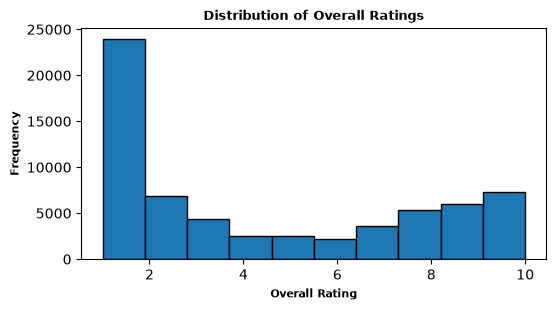

In [65]:
plt.figure(figsize=(6, 3))

plt.hist(df_data['over_all_rating'].dropna(), bins=10, edgecolor='black')

plt.title('Distribution of Overall Ratings',fontsize=9,fontweight='bold')
plt.xlabel('Overall Rating',fontsize=8,fontweight='bold')
plt.ylabel('Frequency',fontsize=8,fontweight='bold')

plt.show()



- The rating distribution shows a noticeable concentration at the lowest rating (1) and the highest rating (10), suggesting mixed customer experiences, with a particularly high number of very low ratings.

#### Satisfaction Level Distribution


In [66]:
# satisfaction_level distribution

df_data['satisfaction_level'].value_counts()

# satisfaction_level percentage distribution

satisfaction_counts=df_data['satisfaction_level'].value_counts().drop('Unknown')
satisfaction_percentage=(satisfaction_counts/satisfaction_counts.sum())*100

print("Satisfaction Level Counts:")
print(satisfaction_counts)

print("\nSatisfaction Level Percentage:")
print(satisfaction_percentage.round(2))

Satisfaction Level Counts:
satisfaction_level
Poor      30762
High      26891
Medium     6907
Name: count, dtype: int64

Satisfaction Level Percentage:
satisfaction_level
Poor      47.65
High      41.65
Medium    10.70
Name: count, dtype: float64


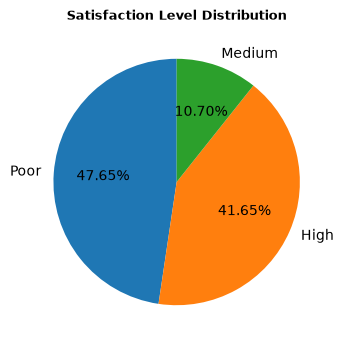

In [67]:

satisfaction_counts = df_data['satisfaction_level'].value_counts()
satisfaction_counts = satisfaction_counts.drop('Unknown', errors='ignore')

plt.figure(figsize=(8, 4))

satisfaction_counts.plot(kind='pie',autopct='%.2f%%',startangle=90)

plt.title('Satisfaction Level Distribution',fontsize=9,fontweight='bold')
plt.ylabel('')
plt.show()

Observations:
- Nearly half of the passengers (47.65%) reported poor satisfaction.
- High satisfaction accounted for 41.65%, while only 10.70% of passengers reported medium satisfaction.
- The Unknown category was excluded because it represents missing overall ratings.
- The result of this distribution indicates that passenger satisfaction is a concern, with poor ratings representing the largest share of reviews.


#### Service Quality Analysis

In [68]:
# Average rating for each services

service_columns=['seat_comfort','cabin_staff_service','food__beverages','inflight_entertainment','ground_service',
                  'value_for_money']

average_service_rating=df_data[service_columns].mean()

print(average_service_rating.round(2))


seat_comfort              2.84
cabin_staff_service       3.07
food__beverages           2.80
inflight_entertainment    2.83
ground_service            2.58
value_for_money           2.61
dtype: float64


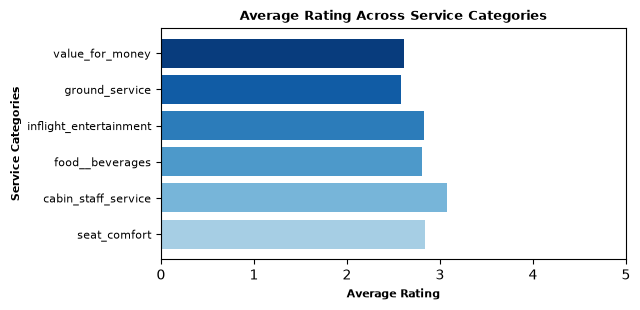

In [69]:
sorted_ratings = average_service_rating.sort_values()

colors = plt.cm.Blues( [0.35 + i * 0.12 for i in range(len(sorted_ratings))])

plt.figure(figsize=(6,3))

plt.barh( average_service_rating.index,average_service_rating.values,color=colors)

plt.title('Average Rating Across Service Categories',fontsize=9, fontweight='bold')
plt.xlabel('Average Rating',fontsize=8, fontweight='bold')
plt.ylabel('Service Categories',fontsize=8, fontweight='bold')
plt.yticks(fontsize=8)
plt.xlim(0, 5)
plt.show()

Observations

- The chart shows that cabin staff service received the highest average rating, followed by seat comfort and inflight entertainment.
- Ground service received the lowest average rating, followed by value for money.
- This indicates that passengers rated cabin staff service relatively highly, while ground service and value for money are the main areas that need improvement.

#### Available Ratings Across Service Categories

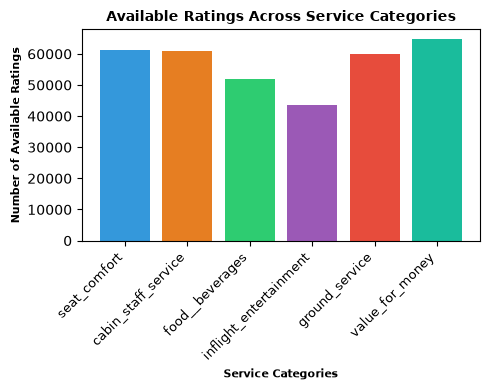

In [70]:

service_counts = df_data[service_columns].count()

plt.figure(figsize=(5, 4))

plt.bar( service_counts.index, service_counts.values, color=['#3498DB', '#E67E22', '#2ECC71',
           '#9B59B6', '#E74C3C', '#1ABC9C'])

plt.title('Available Ratings Across Service Categories',fontsize=10, fontweight='bold')
plt.xlabel('Service Categories',fontsize=8, fontweight='bold')
plt.ylabel('Number of Available Ratings',fontsize=8, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.xticks(fontsize=9)
plt.tight_layout()
plt.show()

Observations:

- Calculated the number of non-null ratings available for each service category.
- Used a bar chart to compare the availability of passenger ratings across service categories.
- This analysis helps identify differences in data availability and understand missing ratings in the dataset.

In [71]:
# Identify the 3 lowest-rated services

lowest_rated_services = average_service_rating.sort_values().head(3)

print("\nThree Lowest-Rated Services:")
print(lowest_rated_services.round(2))



Three Lowest-Rated Services:
ground_service     2.58
value_for_money    2.61
food__beverages    2.80
dtype: float64


- Sorted the average ratings of the six service categories in ascending order.
- Identified the three service categories with the lowest average ratings.
- This helps highlight the service areas that may need improvement.

#### Distribution of Review Counts Across Airlines

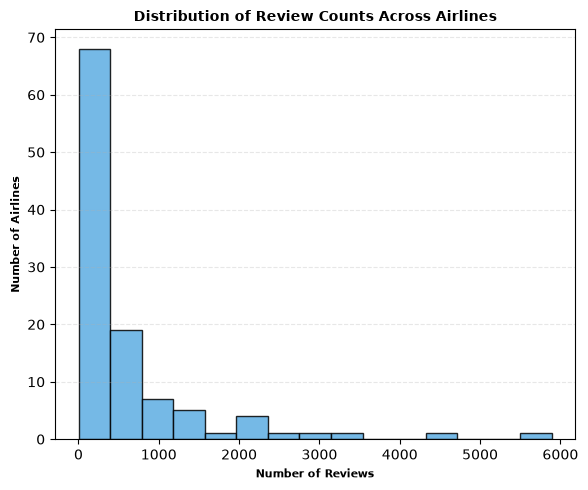

In [72]:
airline_counts = df_data['airline_name'].value_counts()

plt.figure(figsize=(6,5))

plt.hist( airline_counts,bins=15,color='#5DADE2',edgecolor='black',alpha=0.85)

plt.title('Distribution of Review Counts Across Airlines',fontsize=10, fontweight='bold')
plt.xlabel('Number of Reviews',fontsize=8, fontweight='bold')
plt.ylabel('Number of Airlines',fontsize=8, fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


Observations:

- Calculated the number of reviews for each airline.
- Used a histogram to examine the distribution of review counts across airlines.
- Most airlines had fewer than 500 reviews, while only a few airlines had more than 1,000 reviews.
- The distribution is strongly right-skewed, indicating that a small number of airlines received significantly more reviews than others.

##### Bivariate Analysis

#### Overall Rating vs Recommendation Analysis

In [73]:
# Average overall_rating by recommendation

recommended_analysis=df_data[df_data['recommended'].isin(['yes', 'no'])].groupby('recommended')['over_all_rating']
    .mean().round(2)

print(recommended_analysis)


recommended
no     1.87
yes    8.34
Name: over_all_rating, dtype: float64


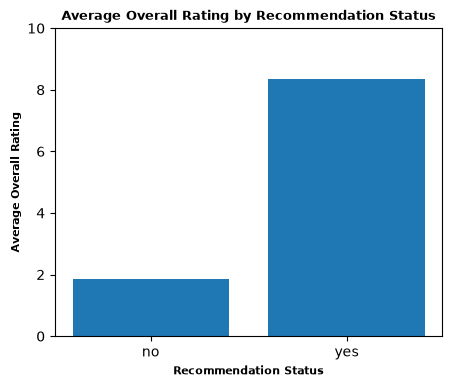

In [74]:
plt.figure(figsize=(5,4))

plt.bar( recommended_analysis.index,recommended_analysis.values)

plt.title('Average Overall Rating by Recommendation Status',fontsize=9,fontweight='bold')
plt.xlabel('Recommendation Status',fontsize=8,fontweight='bold')
plt.ylabel('Average Overall Rating',fontsize=8,fontweight='bold')
plt.ylim(0, 10)


plt.show()



Observations:

- Grouped the reviews by recommendation status and calculated the average overall rating for each category.
- Passengers who recommended the airline (Yes) gave a higher average rating (8.34) compared to those who did not recommend it (No), whose average rating was 1.87.
- This shows a clear difference in overall ratings between passengers who recommended and did not recommend the airline.

#### Airline-wise Average Overall Rating


In [75]:
airline_analysis=(df_data.groupby('airline_name')['over_all_rating'].agg(['count','mean'])
    .sort_values(by='mean',ascending=False).reset_index())

print(airline_analysis.round(2))

                  airline_name  count  mean
0               japan-airlines      2  8.50
1              hainan-airlines    339  8.49
2      china-southern-airlines   1729  7.99
3             garuda-indonesia    680  7.95
4    myanmar-national-airlines     15  7.87
..                         ...    ...   ...
104            united-airlines   4510  2.75
105          american-airlines   5890  2.28
106                ita-airways    269  2.23
107                      goair    190  1.92
108             silver-airways    220  1.82

[109 rows x 3 columns]


In [76]:
# Check the distribution of airline records

airline_counts = df_data['airline_name'].value_counts()

print(airline_counts.describe())


count     109.000000
mean      593.357798
std       913.198860
min         2.000000
25%        70.000000
50%       270.000000
75%       659.000000
max      5893.000000
Name: count, dtype: float64


- I checked the distribution of records using descriptive statistics. The first quartile was 70 and the median was 270. I noticed that some airlines had very few records, which could make their average ratings less representative. Therefore, I selected 100 records as a practical minimum threshold for comparison.

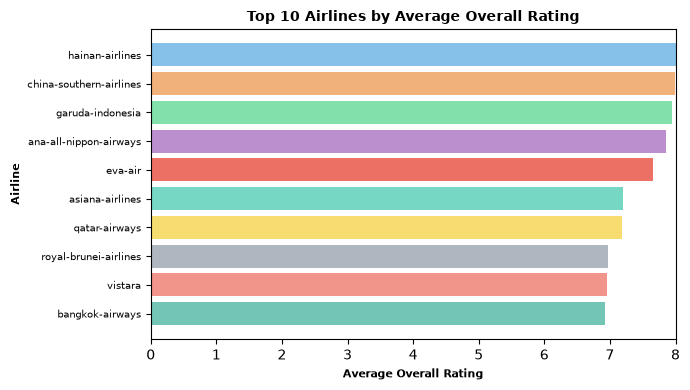

In [112]:
# Filter airlines with at least 100 reviews
airline_filtered = airline_analysis[airline_analysis['count'] >= 100]

# Select the Top 10 airlines
top_10_airlines = airline_filtered.head(10)

plt.figure(figsize=(7,4))
colors = [
    '#85C1E9', '#F0B27A', '#82E0AA', '#BB8FCE',
    '#EC7063', '#76D7C4', '#F7DC6F', '#AEB6BF',
    '#F1948A', '#73C6B6'
]
   
plt.barh( top_10_airlines['airline_name'],top_10_airlines['mean'],color=colors)

plt.title('Top 10 Airlines by Average Overall Rating',fontsize=10, fontweight='bold')
plt.xlabel('Average Overall Rating',fontsize=8, fontweight='bold')
plt.ylabel('Airline',fontsize=8, fontweight='bold')
plt.yticks(fontsize=7)
plt.xlim(0, 8)

plt.gca().invert_yaxis()


plt.tight_layout()
plt.show()

    

Observations:

- Grouped the dataset by airline and calculated the review count and average overall rating.
- Applied a minimum threshold of 100 reviews to exclude airlines with very few reviews.
- Selected the top 10 airlines based on average overall rating.
- Hainan Airlines recorded the highest average overall rating of 8.49.
- This filtering helps make the comparison more meaningful by considering airlines with a reasonable number of reviews.

#### Traveller Type-wise Overall Rating Analysis

In [78]:
# Calculate average overall rating by traveller type

traveller_analysis=(df_data.groupby('type_of_traveller')['over_all_rating'].agg(['count','mean']))

print(traveller_analysis.round(2))

                   count  mean
type_of_traveller             
business           10940  4.15
couple_leisure     15040  4.01
family_leisure     12850  3.82
solo_leisure       25730  4.89


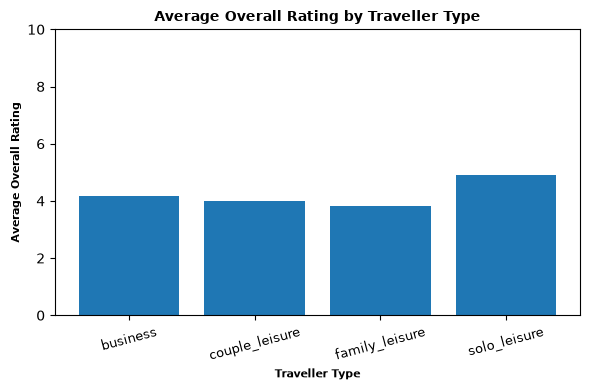

In [79]:
plt.figure(figsize=(6, 4))

plt.bar(
    traveller_analysis.index,
    traveller_analysis['mean'],
)

plt.title('Average Overall Rating by Traveller Type',fontsize=10, fontweight='bold')
plt.xlabel('Traveller Type', fontsize=8, fontweight='bold')
plt.ylabel('Average Overall Rating', fontsize=8, fontweight='bold')

plt.ylim(0, 10)
plt.xticks(rotation=15)
plt.xticks(fontsize=9)
plt.tight_layout()
plt.show()


Observations:

- Grouped the data by traveller type and calculated the count and average overall rating.
- Excluded records with Unknown traveller types.
- Used a bar chart to compare average ratings across traveller categories.
- Solo leisure travellers recorded the highest average rating (4.76), while family leisure travellers recorded the lowest (3.82).

##### Univariate(Seaborn)

#### Trip Verification Status Distribution

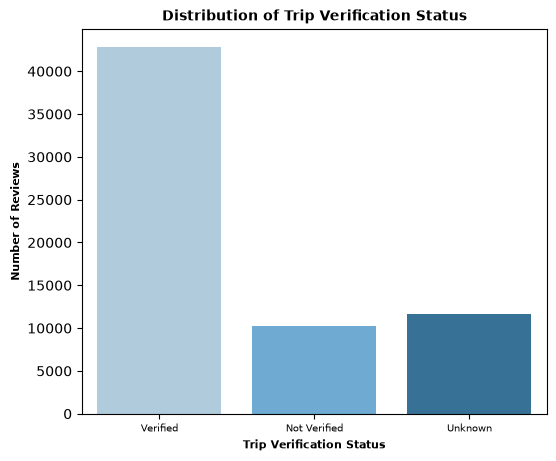

In [114]:
plt.figure(figsize=(6, 5))

sns.countplot(data=df_data,x='trip_verified',hue='trip_verified',palette=['#A9CCE3','#5DADE2','#2874A6'],legend=False)

plt.title('Distribution of Trip Verification Status',fontsize=10,fontweight='bold')
plt.xlabel('Trip Verification Status',fontsize=8,fontweight='bold')
plt.ylabel('Number of Reviews', fontsize=8,fontweight='bold')
plt.xticks(fontsize=7)
plt.show()



Observations:

- Used Seaborn's count plot to visualize the distribution of trip verification status.
- Compared the number of Verified, Not Verified and Unknown reviews.
- Verified reviews recorded the highest count, with approximately 40,000 above reviews.
- Not Verified and Unknown categories recorded considerably fewer reviews.
- This indicates that verified reviews make up the largest share of the dataset.



#### Overall Rating Distribution


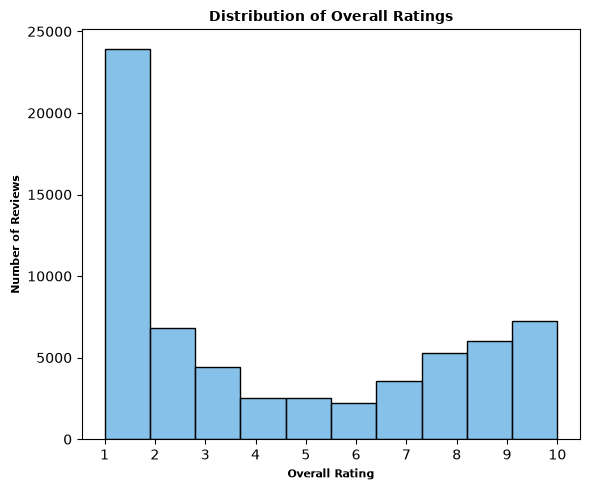

In [81]:

plt.figure(figsize=(6, 5))

sns.histplot(data=df_data, x='over_all_rating',bins=10,color='#5DADE2',edgecolor='black')

plt.title('Distribution of Overall Ratings',fontsize=10,fontweight='bold')
plt.xlabel('Overall Rating',fontsize=8, fontweight='bold')
plt.ylabel('Number of Reviews',fontsize=8, fontweight='bold')

plt.xticks(range(1, 11))
plt.tight_layout()
plt.show()


Observations:

- Used Seaborn's histogram to visualize the frequency distribution of overall ratings.
- Observed a high frequency of low ratings, particularly rating 1.
- Ratings between 7 and 10 also recorded considerable frequencies, while middle ratings had comparatively fewer reviews.
- The distribution indicates that passenger opinions were divided between low and high ratings.

##### Bivariate Analysis

#### Customer Satisfaction Analysis by Seat Type

In [82]:

seat_satisfaction = df_data.groupby( ['seat_type','satisfaction_level']).size().reset_index(name='count')

#print(seat_satisfaction)


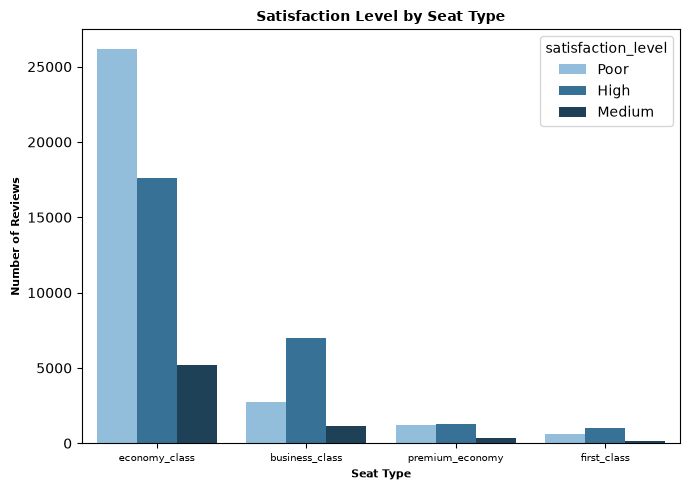

In [115]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_data[df_data['satisfaction_level'] != 'Unknown'],x='seat_type',hue='satisfaction_level',
    palette=['#85C1E9','#2874A6','#154360'])

plt.title('Satisfaction Level by Seat Type',fontsize=10,fontweight='bold')
plt.xlabel('Seat Type',fontsize=8,fontweight='bold')
plt.ylabel('Number of Reviews',fontsize=8,fontweight='bold')
plt.xticks(fontsize=7)
plt.tight_layout()
plt.show()

Observations:

- This analysis examines the distribution of High, Medium, and Poor customer satisfaction levels across different seat types.
- It helps identify differences in customer satisfaction among Business Class, Economy Class, First Class, and Premium Economy passengers.
- Economy Class has many more reviews than the other categories, so its counts are naturally higher.    

#### Global Analysis: Airline Performance Comparison¶

##### Comparison Based on Average Overall Rating and High Customer Satisfaction

In [109]:
# Calculate average overall rating for each airline

rating_analysis = (df_data.groupby('airline_name')['over_all_rating']
    .agg(['count', 'mean'])
    .reset_index()
)

rating_analysis.columns = ['airline_name','review_count','average_overall_rating']

# Exclude Unknown satisfaction values

global_satisfaction = df_data[df_data['satisfaction_level'] != 'Unknown']

# Calculate High satisfaction percentage

high_satisfaction = (global_satisfaction.groupby('airline_name')['satisfaction_level']
    .apply(lambda x: (x == 'High').mean() * 100)
    .reset_index(name='high_satisfaction_percentage')
)
# Merge both analysis results

global_airline_comparison = pd.merge(rating_analysis,high_satisfaction,on='airline_name',how='inner')

# Filter airlines with at least 100 reviews

global_airline_comparison = global_airline_comparison[global_airline_comparison['review_count'] >= 100]

# Sort by average overall rating

global_airline_comparison.sort_values( by='average_overall_rating',ascending=False).head(10).round(2)


,airline_name,review_count,average_overall_rating,high_satisfaction_percentage
53,hainan-airlines,339,8.49,92.04
38,china-southern-airlines,1729,7.99,90.69
50,garuda-indonesia,680,7.95,86.47
25,ana-all-nippon-airways,380,7.86,86.58
47,eva-air,390,7.66,84.87
26,asiana-airlines,240,7.20,80.83
84,qatar-airways,2294,7.19,78.16
85,royal-brunei-airlines,120,6.98,78.33
107,vistara,279,6.95,72.40
29,bangkok-airways,230,6.93,76.96


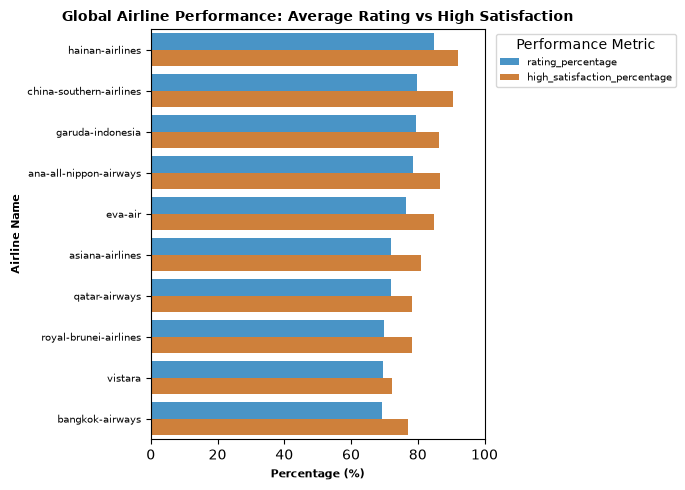

In [123]:
# Select top 10 airlines based on average overall rating

top_10 = global_airline_comparison.nlargest( 10, 'average_overall_rating').copy()

# Convert average rating to percentage scale
top_10['rating_percentage'] = (top_10['average_overall_rating'] * 10
)
# Reshape data for grouped bar chart
chart_data = top_10.melt(
    id_vars='airline_name',
    value_vars=['rating_percentage','high_satisfaction_percentage'],
    var_name='Metric',
    value_name='Percentage'
)

plt.figure(figsize=(7,5))

sns.barplot(
    data=chart_data,
    x='Percentage',
    y='airline_name',
    hue='Metric',
    palette=['#3498DB', '#E67E22']
)

plt.title('Global Airline Performance: Average Rating vs High Satisfaction',fontsize=10,fontweight='bold')
plt.xlabel('Percentage (%)',fontsize=8, fontweight='bold')
plt.ylabel('Airline Name',fontsize=8, fontweight='bold')
plt.yticks(fontsize=7)
plt.xlim(0,100)

plt.legend(title='Performance Metric',
           fontsize=7,
           loc='upper left',
           bbox_to_anchor=(1.02, 1))

plt.tight_layout()

Observations:

- The analysis highlights differences in airline performance based on average overall customer ratings and High satisfaction percentage.
- Airlines with higher average overall ratings generally indicate better customer experiences.
- A higher High satisfaction percentage indicates that a larger proportion of customers reported high satisfaction.
- Comparing both metrics helps identify airlines that perform well in terms of both customer ratings and satisfaction.
- The results provide an overall understanding of customer satisfaction across different airlines.

##### Multivariate Analysis

#### Hainan Airlines: Overall Ratings by Review Verification and Recommendation Status

Hainan Airlines Dataset: (340, 19)


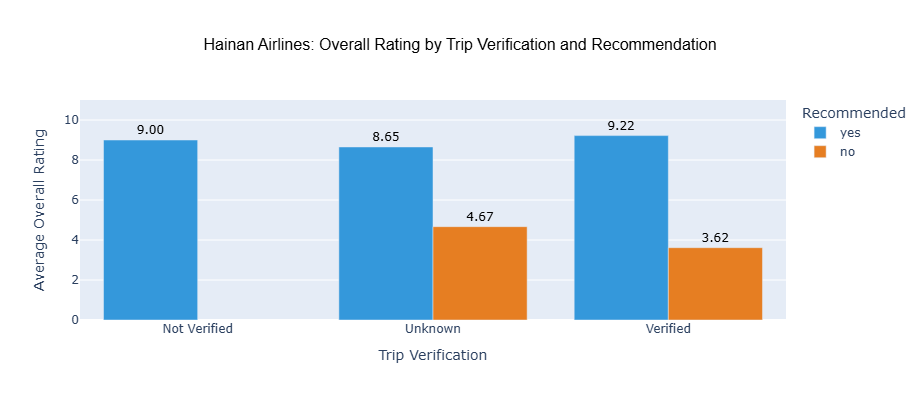

In [104]:
# Step 1: Filter Hainan Airlines
hainan_df = df_data[df_data['airline_name'].str.strip().str.lower() == 'hainan-airlines'].copy()

print("Hainan Airlines Dataset:",hainan_df.shape)

# Step 2: Multivariate Analysis
hainan_analysis = hainan_df.groupby(['trip_verified','recommended'])['over_all_rating'].agg( ['count', 'mean']).round(2)

#print(hainan_analysis)

# Step 3: Prepare data for chart
hainan_plot = hainan_df.groupby(['trip_verified','recommended'])['over_all_rating'].mean().reset_index()

# Step 4: Create grouped bar chart
fig = px.bar( hainan_plot,
    x='trip_verified',
    y='over_all_rating',
    color='recommended',
    barmode='group',
    text_auto='.2f',
    title='Hainan Airlines: Overall Rating by Trip Verification and Recommendation',
    labels={'trip_verified': 'Trip Verification','over_all_rating': 'Average Overall Rating',
        'recommended': 'Recommended'
    },
    color_discrete_map={'yes': '#3498DB','no': '#E67E22'}
)

# Step 5: Customize chart

fig.update_traces( textposition='outside',
    textfont=dict(size=12, color='black')
)

fig.update_layout(title=dict( font=dict(size=16, color='black',family='Arial')),
    title_x=0.5,
    width=800,
    height=400,
    yaxis=dict(range=[0, 11],title='Average Overall Rating'
    ),
    xaxis_title='Trip Verification',
    legend_title='Recommended',
     font=dict(size=12)
)

fig.show()

Key Findings:
- Verified customers who recommended the airline gave the highest average rating of 9.22 (269 reviews).
- Verified customers who did not recommend the airline gave a low average rating of 3.62 (39 reviews).
- Not verified customers who recommended the airline gave an average rating of 9.00 (5 reviews).
- Customers who recommended the airline generally gave higher overall ratings than those who did not.

#### Airline Service Quality Comparison


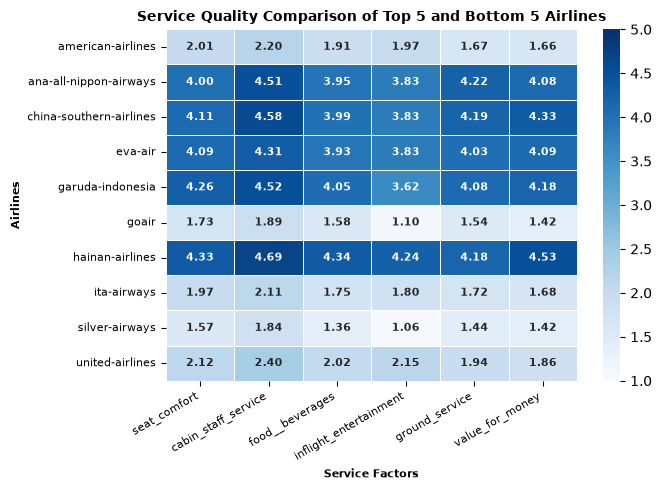

In [105]:
# Calculate the average overall rating and review count for each airline

rating_analysis = (
    df_data.groupby('airline_name')['over_all_rating']
    .agg(['count', 'mean'])
    .reset_index())

rating_analysis.columns = [
    'airline_name', 'review_count', 'average_overall_rating']

# Consider airlines with at least 100 reviews
rating_analysis = rating_analysis[
    rating_analysis['review_count'] >= 100]

# Select top 5 and bottom 5 airlines
top_5 = rating_analysis.nlargest(5,'average_overall_rating')

bottom_5 = rating_analysis.nsmallest(5,'average_overall_rating')

#print("Top 5 Airlines:")
#print(top_5)

# Combine top 5 and bottom 5 airlines
selected_airlines = pd.concat([top_5, bottom_5])

# Calculate average service ratings for each airline
service_comparison = (
    df_data[df_data['airline_name'].isin(selected_airlines['airline_name'])]
    .groupby('airline_name')[service_columns].mean().round(2)
)

plt.figure(figsize=(7,5))

sns.heatmap(
    service_comparison,
    annot=True,
    cmap='Blues',
    fmt='.2f',
    linewidths=0.5,
    linecolor='white',
    vmin=1,
    vmax=5,
    annot_kws={'size': 8,'weight':'bold'})

plt.title(
    'Service Quality Comparison of Top 5 and Bottom 5 Airlines',
    fontsize=10,
    fontweight='bold')

plt.xlabel('Service Factors', fontsize=8, fontweight='bold')
plt.ylabel('Airlines', fontsize=8, fontweight='bold')

plt.xticks(rotation=30, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()



Observations and Findings – Airline Service Quality Comparison
- Hainan Airlines shows the highest overall rating (8.49) and strong service ratings across all six factors.
- China Southern Airlines and Garuda Indonesia also show consistently high service ratings.
- Cabin staff service is one of the strongest service factors among the top-performing airlines.
- Silver Airways, GoAir and ITA Airways show comparatively low ratings across most service factors.
- Inflight entertainment and ground service are particularly weak areas among some of the bottom-performing airlines.
- Value for money is rated highly by top-performing airlines, especially Hainan Airlines, while it receives lower ratings among the bottom-performing airlines.

#### Average Overall Rating by Traveller Type and Seat Type


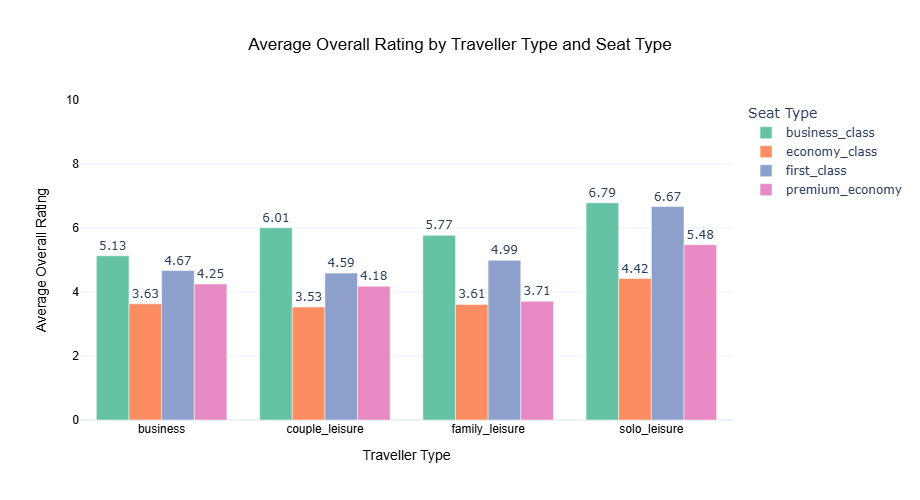

In [97]:
# Calculate average rating by traveller type and seat type

traveller_seat_analysis = (
    df_data.groupby(['type_of_traveller','seat_type'])['over_all_rating'].mean() .reset_index())

traveller_seat_analysis['over_all_rating'] = (traveller_seat_analysis['over_all_rating'].round(2))

# Create grouped bar chart

fig = px.bar(traveller_seat_analysis,
    x='type_of_traveller',
    y='over_all_rating',
    color='seat_type',
    barmode='group',
    title='Average Overall Rating by Traveller Type and Seat Type',
    labels={'type_of_traveller':'Traveller Type','seat_type': 'Seat Type','over_all_rating':'Average Overall Rating' },
    color_discrete_sequence=px.colors.qualitative.Set2,
    text_auto='.2f'
)

fig.update_layout(
    title_font=dict(size=17, family='Arial', color='black'),
    title_x=0.5,title_xanchor='center',

    xaxis=dict(
        title=dict(text='Traveller Type', font=dict(size=14, family='Arial', color='black')),
        tickfont=dict(size=12, family='Arial', color='black')
    ),

    yaxis=dict(
        title=dict(text='Average Overall Rating', font=dict(size=14, family='Arial', color='black')),
        tickfont=dict(size=12, family='Arial', color='black'),
        range=[0, 10]
    ),
    width=800,
    height=500,
    template='plotly_white',
    legend_title='Seat Type'
)

fig.update_traces(
    textposition='outside'
)

fig.show()


Observations:
- Solo Leisure travellers in Business Class received the highest average overall rating of 6.79, followed by First Class at 6.67.
- Business Class received the highest average ratings across all four traveller types.
- Economy Class received comparatively lower ratings across all traveller types.
- Couple Leisure travellers in Economy Class recorded the lowest average rating of 3.53.
- Solo Leisure travellers showed higher average ratings across all four seat categories compared with the other traveller types.
- Premium Economy ratings were also relatively higher among Solo Leisure travellers, with an average rating of 5.48.

**Overall Finding:**

- The analysis shows that average overall ratings vary across traveller types and seat categories. Business Class generally received higher ratings, while Economy Class received lower ratings. Solo Leisure travellers recorded comparatively higher ratings across the different seat categories.

#### Correlation Between Service Ratings

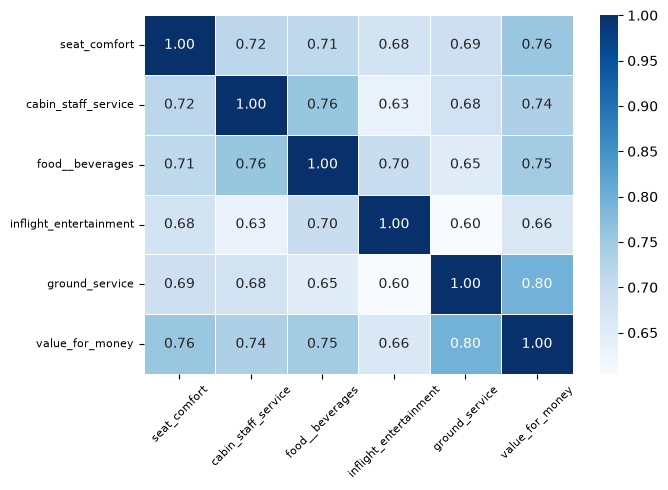

In [126]:
# Select service rating columns

service_columns = ['seat_comfort','cabin_staff_service','food__beverages','inflight_entertainment',
                   'ground_service','value_for_money']

# Calculate correlation
service_corr = df_data[service_columns].corr()

# Plot heatmap
plt.figure(figsize=(7,5))

sns.heatmap( service_corr,annot=True,cmap='Blues',fmt='.2f',linewidths=0.5)
plt.xticks(fontsize=8, rotation=45)
plt.yticks(fontsize=8)
plt.tight_layout()


Observations:

- All six service factors show positive correlations with each other.
- Ground Service and Value for Money have the strongest positive correlation (0.80).
- Cabin Staff Service and Food & Beverages also show a strong positive correlation (0.76).
- Seat Comfort and Value for Money have a positive correlation of 0.76.
- Inflight Entertainment and Ground Service show the lowest correlation (0.60), but the relationship is still positive.
- Overall, the service factors are positively related, indicating that customers who give higher ratings to one service area tend to give higher ratings to other service areas as well.

**Overall Finding:**

- The heatmap shows positive relationships among all six service factors. Ground Service and Value for Money have the strongest relationship, while Inflight Entertainment and Ground Service have the weakest relationship.

#### High Customer Satisfaction by Indian Airline,Traveller Type and Seat Type

In [89]:
# Identify Indian Airlines

indian_airline_names = ['air-india','spicejet','vistara','goair','air-india-express','airasia-india']

indian_airlines = df_data[df_data['airline_name'].isin(indian_airline_names)].copy()

print(indian_airlines['airline_name'].value_counts())

airline_name
air-india            1210
spicejet              610
vistara               279
goair                 190
air-india-express     140
airasia-india         124
Name: count, dtype: int64


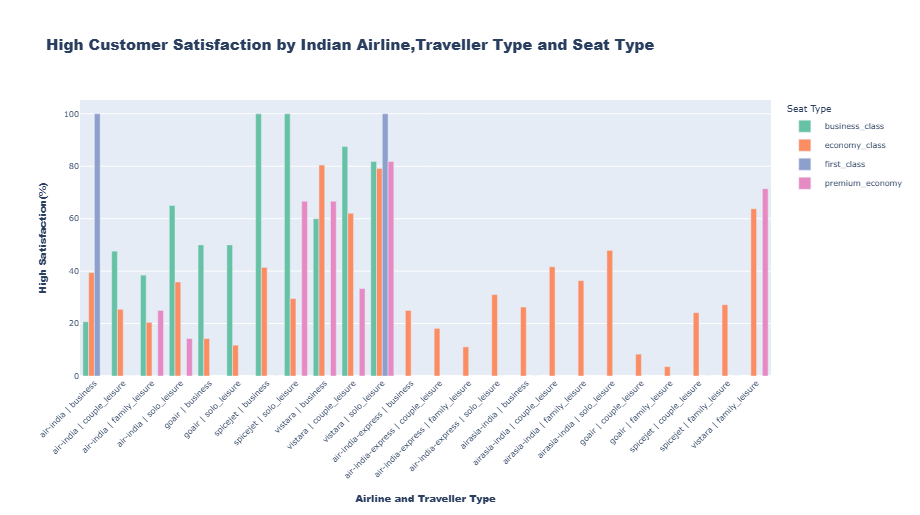

In [90]:
# Step 1: Exclude Unknown satisfaction levels

indian_analysis = indian_airlines[
    indian_airlines['satisfaction_level'] != 'Unknown'].copy()

# Step 2: Create customer satisfaction summary
customer_satisfaction_filtered = (indian_analysis
    .groupby(['airline_name','type_of_traveller','seat_type'])
    .agg(total_reviews=('satisfaction_level','count'),high_satisfaction=('satisfaction_level',
                           lambda x: (x == 'High').sum()))
    .reset_index()
)

# Step 3: Calculate high satisfaction percentage

customer_satisfaction_filtered['high_satisfaction_percentage'] = (
    customer_satisfaction_filtered['high_satisfaction']/ customer_satisfaction_filtered['total_reviews'] * 100
)
# Combine airline name and traveller type
customer_satisfaction_filtered['airline_traveller'] = (
    customer_satisfaction_filtered['airline_name'] + ' | ' +
    customer_satisfaction_filtered['type_of_traveller']
)

# Create grouped bar chart

fig = px.bar(customer_satisfaction_filtered,
              x='airline_traveller',y='high_satisfaction_percentage',
    color='seat_type', barmode='group',hover_data=['airline_name','type_of_traveller',
        'total_reviews','high_satisfaction'],
    title='High Customer Satisfaction by Indian Airline,Traveller Type and Seat Type',
    color_discrete_sequence=px.colors.qualitative.Set2)

# Update chart layout

fig.update_layout(title=dict( font=dict(size=15, family='Arial black')),height=500,width=1000,
  xaxis=dict(
        title=dict(
            text='Airline and Traveller Type',
            font=dict(size=10, family='Arial Black')),tickfont=dict(size=8),tickangle=-45),
                     yaxis=dict( title=dict(text='High Satisfaction(%)',font=dict(size=10, family='Arial Black')),
                     tickfont=dict(size=8)),

    legend=dict(title=dict(text='Seat Type',font=dict(size=9)),font=dict(size=8))
)


Objective:
- To analyse how customer satisfaction varies across Indian airlines based on traveller type and seat type.

Key observations
1. Vistara
    
- Vistara appeared frequently among the highest satisfaction combinations.
- Its Solo Leisure passengers in Premium Economy had the highest percentage in the displayed results: 81.82%.
- Its Business and Solo Leisure travellers in Economy also showed high satisfaction percentages.
    
2. Air India
    
- Solo Leisure travellers in Business class showed 65% high satisfaction.
- Couple Leisure travellers in Business class showed 47.62%.
- Business and Family Leisure travellers in Economy showed lower percentages in the displayed combinations.
    
Conclusion:

- The analysis shows that customer satisfaction varies across airlines, traveller types and seat types. Vistara appeared among the leading combinations in the results, indicating comparatively higher satisfaction in some passenger groups. This analysis helps identify passenger groups with higher satisfaction and areas where airlines may need to improve their service quality.

#### 1.Service Quality of Highly Satisfied Passengers in Indian Airlines

In [91]:
# Filter highly satisfied passengers

indian_high_satisfaction = indian_analysis[
    indian_analysis['satisfaction_level'] == 'High']

# Compare average service ratings
service_columns = ['seat_comfort','cabin_staff_service','food__beverages','inflight_entertainment',
                   'ground_service','value_for_money']

indian_service_analysis = ( indian_high_satisfaction[service_columns].mean().sort_values(ascending=False))

print(indian_service_analysis.round(2))

cabin_staff_service       4.36
value_for_money           4.36
ground_service            4.22
seat_comfort              4.20
food__beverages           4.04
inflight_entertainment    3.40
dtype: float64


Key observations:
    
1. Value for money received the highest average rating (4.38), indicating that highly satisfied passengers rated the value they received positively.
2. Cabin staff service ranked second with 4.28, showing positive feedback about cabin crew service.
3. Ground service also received a good rating of 4.13.
4. Inflight entertainment received the lowest rating (3.22), making it the comparatively weaker-rated service factor among these passengers.

#### 2. Poorly Satisfied passengers in Indian airlines.

In [92]:
# Filter Poor satisfaction passengers

indian_poor_satisfaction = indian_analysis[
    indian_analysis['satisfaction_level'] == 'Poor']

# Calculate average service ratings

indian_poor_service_analysis = (indian_poor_satisfaction[service_columns] .mean().sort_values(ascending=False))

print(indian_poor_service_analysis.round(2))



cabin_staff_service       1.76
food__beverages           1.59
seat_comfort              1.58
ground_service            1.33
inflight_entertainment    1.25
value_for_money           1.24
dtype: float64


Key Findings:

- Cabin Staff Service is comparatively the best-rated service factor among the six categories.
- Inflight Entertainment receives the lowest average rating, indicating an area that needs improvement.
- Value for Money and Ground Service also receive relatively low ratings.
- Overall, the average ratings suggest that customers are not highly satisfied with the airline servicers factors.

#### 3.Service Rating Comparison: High vs Poor Satisfaction

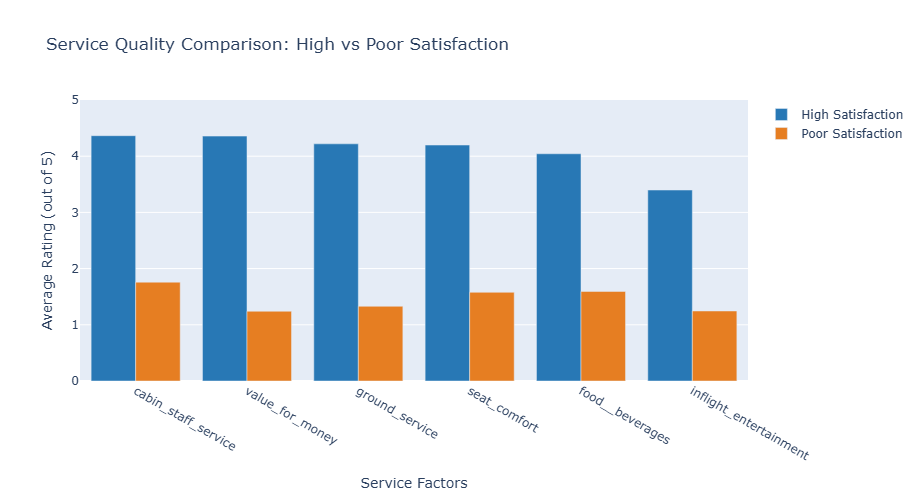

In [107]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Bar(
    x=indian_service_analysis.index,
    y=indian_service_analysis.values,
    name='High Satisfaction',
    marker_color='#2878B5'
))

fig.add_trace(go.Bar(
    x=indian_poor_service_analysis.index,
    y=indian_poor_service_analysis.values,
    name='Poor Satisfaction',
    marker_color='#E67E22'
))

fig.update_layout(
    title='Service Quality Comparison: High vs Poor Satisfaction',
    xaxis_title='Service Factors',
    yaxis_title='Average Rating (out of 5)',
    barmode='group',
    yaxis=dict(range=[0, 5]),
    height=500,
    width=700
)

Key findings:
- Value for money showed the largest difference between the two groups.
- Ground service and cabin staff service also showed considerable differences.
- Inflight entertainment received the lowest average rating in both groups.
- All six service factors received higher average ratings from highly satisfied passengers.

### Important Findings and Key Insights from the Project

**1. Overall Customer Rating Distribution**
    
##### Important Findings:

- The average overall customer rating was 4.34 out of 10.
- The median rating was 3, indicating that half of the customers gave ratings of 3 or below.
- The most frequently given rating was 1.
    
##### Key Insight:
    
- The overall customer rating distribution indicates a considerable concentration of low ratings, suggesting that customer experience and service quality need improvement across the airlines included in the dataset.

**2. Customer Satisfaction Distribution**

##### Important Findings:

- Poor satisfaction represented 47.65% of reviews.
- High satisfaction accounted for 41.65%.
- Medium satisfaction accounted for 10.70%.
- Poor satisfaction was more common than high satisfaction.
    
##### Key Insight:

- Nearly half of the customers reported poor satisfaction. This indicates that a significant proportion of passengers had unsatisfactory experiences, highlighting the need for improvements in airline services.

**3. Global Airline Performance Comparison**

##### Important Findings
                                                                                                                                                                       
- Hainan Airlines recorded the highest average overall rating of 8.49.
- China Southern Airlines followed with 7.99.                                       
- Garuda Indonesia recorded 7.95.
- Silver Airways recorded the lowest average rating of 1.82, followed by GoAir at 1.92.
- The comparison included airlines with at least 100 reviews.

##### Key Insight:

- Hainan Airlines emerged as the highest-rated airline, while Silver Airways recorded the lowest rating. The considerable difference in ratings highlights variations in customer experience across airlines. Based on this finding, Hainan Airlines was selected for further detailed analysis.

**4. Detailed Multivariate Analysis of Hainan Airlines**

##### Important Findings:

- Verified customers who recommended Hainan Airlines recorded the highest average overall rating of 9.22 (269 reviews).
- Verified customers who did not recommend the airline recorded an average rating of 3.62 (39 reviews).
- Not verified customers who recommended the airline gave an average rating of 9.00 (5 reviews).
- Customers with unknown verification status who recommended the airline recorded an average rating of 8.65 (23 reviews).

##### Key Insight:

- Customers who recommended Hainan Airlines gave considerably higher overall ratings than those who did not. The difference between verified customers who recommended and did not recommend the airline indicates a strong relationship between customer ratings and recommendation behaviour.

**5. Global Service Quality Analysis**

##### Important Findings:
    
- Cabin staff service received the highest average rating of 3.07.
- Ground service received the lowest average rating of 2.58.
- The remaining service factors also received moderate ratings.

##### Key Insight:

- Cabin staff service performed relatively better than the other service factors, whereas ground service was the weakest area. Airlines should focus more on improving ground services to enhance the overall passenger experience.

**6. Traveller Type and Seat Type Analysis**
    
##### Important Findings:
    
- Business Class generally received higher average overall ratings across the traveller types shown in the chart.
- Solo Leisure travellers in Business Class recorded the highest average rating of 6.79.
- Couple Leisure travellers in Economy Class recorded the lowest average rating of 3.53.
- Economy Class accounted for the highest number of reviews.
##### Key Insight:

- Customer ratings varied according to traveller type and seat category. Business Class passengers generally reported better experiences, while Economy Class passengers showed comparatively lower ratings in some traveller groups. This highlights the importance of understanding different passenger expectations.

**7. Correlation Between Service Ratings**

##### Important Findings:
    
- All six service factors showed positive correlations with one another.
- Ground service and value for money had the strongest correlation of 0.80.
- Inflight entertainment and ground service had the weakest correlation of 0.60.

##### Key Insight:

- The positive correlations indicate that customers who rated one service factor highly tended to rate other service factors highly as well. Ground service and value for money showed the strongest relationship, suggesting that improvements in these areas may be associated with better customer perceptions of other services.

**8. Indian Airline Customer Satisfaction**

##### Important Findings:
    
- Vistara appeared frequently among the combinations with higher satisfaction percentages.
- Solo Leisure passengers in Vistara Premium Economy recorded the highest satisfaction percentage among the displayed combinations at 81.82%.
- Satisfaction varied across airlines, traveller types and seat categories.

##### Key Insight:

- Customer satisfaction differed across Indian airlines and passenger categories. Vistara showed strong satisfaction in several combinations, particularly among Solo Leisure passengers travelling in Premium Economy. This indicates that airline performance can vary depending on passenger type and seat category.

**9. Indian Airline Service Quality**
    
##### Important Findings:
    
- Among highly satisfied passengers, value for money received the highest average rating of 4.38, followed by cabin staff service at 4.28.
- Among poorly satisfied passengers, cabin staff service received the highest average rating of 1.76, while value for money received the lowest at 1.24.
- Value for money showed the largest difference between highly satisfied and poorly satisfied passengers.
- Ground service and cabin staff service also showed considerable differences.
- Inflight entertainment remained a comparatively weaker-rated factor even among highly satisfied passengers.

##### Key Insight:

- Value for money was the strongest differentiating factor between highly satisfied and poorly satisfied passengers. Although cabin staff service performed relatively well among highly satisfied customers, value for money and ground service need particular attention to improve customer satisfaction across Indian airlines.